Example 5: Free-radical polymerization by the method of moments.

A port of the standalone ``polymerization_moments.py`` demo onto the
ReactionModel API. It makes one point: a mechanistic fit recovers a quantity the
instrument never measures.

NOTE: every number here is SYNTHETIC. The rate constants, initial charges, noise
level, and the "measured" monomer trace are all generated by the model in this
file. Nothing was measured in a lab. The values are chosen to be qualitatively
like a real free-radical polymerization; they are not fitted to or validated
against experimental data. These scripts demonstrate method behaviour, not
physical parameter values.

The chemistry is free-radical polymerization terminating by disproportionation.
Initiator decomposes, ``I -> 2 R`` at rate ``kd``, seeding radicals at
``RI = 2 f kd I``. Radicals propagate, ``P_n + M -> P_{n+1}`` at rate ``kp``, and
terminate, ``P_n + P_m -> D_n + D_m`` at rate ``kt``. The infinite set of
chain-length balances is closed by the method of moments into eight ordinary
differential equations: monomer ``M``, initiator ``I``, the live (radical)
moments ``Y0, Y1, Y2``, and the dead (polymer) moments ``X0, X1, X2``. The k-th
moment is ``sum_n n^k [chains of length n]``, so ``X0`` counts dead chains,
``X1`` counts monomer units locked into dead chains, and ``X2`` weights those
units again by chain length.

The payoff is what the moments buy. A Raman or UV probe watching the reaction
sees the C=C stretch disappear, which is monomer, which is conversion. It never
sees molecular weight. But fitting the moment mechanism to that one conversion
signal both recovers the propagation rate constant and reconstructs the
molecular-weight distribution the probe cannot see: the number-average degree of
polymerization ``Mn = X1 / X0``, the weight-average ``Mw = X2 / X1``, and the
polydispersity index ``PDI = Mw / Mn``. Termination by pure disproportionation
gives an INSTANTANEOUS PDI of 2.0 (a most-probable distribution). The cumulative
PDI of all dead chains, which is what the moments track, sits somewhat above 2.0
because monomer depletion and initiator decay make the kinetic chain length
drift over the batch, broadening the pooled distribution. Here it lands near 2.3,
and the honest test is not that the fit hits 2.0 but that the inferred cumulative
PDI matches the true cumulative PDI, which it does, without the probe ever seeing
a molecular weight.

Two things are worth stating honestly. The first is identifiability. From
conversion alone the mechanism is not fully identifiable: integrating the
monomer balance under the radical quasi-steady-state gives
``-ln(M / M0) = A (1 - e^{-kd t / 2})`` with a single lumped amplitude
``A ~ kp / sqrt(kt)``, so only the ratio ``kp / sqrt(kt)`` is seen, not ``kp``
and ``kt`` separately. If both were estimated the fit would be degenerate, a
ridge of equally good ``(kp, kt)`` pairs. So ``kt`` is FIXED at a known value
(as are ``kd``, an independently measured initiator property, and the efficiency
``f``), and only ``kp`` is estimated. Separating ``kt`` would require
molecular-weight data such as GPC, which is exactly the same lesson as ``Ks`` in
the bioreactor example. The second is that the estimate here comes from a single
scalar parameter fit to a clean, well-sampled conversion curve, so a tenth of a
percent on ``kp`` is expected; on real, drift-laden spectra it would be looser.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import os

## Setup: helper functions and synthetic-data generators

These are lifted verbatim from the example script (`kipetax/examples/Ex_5_polymerization_moments.py`).

In [2]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp

from kipetax import ReactionModel

# ── True system (what we will try to recover) ──
KP, KT, KD, F = 1.0e3, 5.0e3, 0.5, 0.5   # kp estimated; kt, kd, f held known
M0, I0 = 1.0, 0.02                       # initial monomer, initiator charge
TF = 10.0                                # batch duration

# Measurement design: probe samples from t=0.5 h, but the state starts at t=0.
T_DATA = np.linspace(0.5, TF, 30)
NOISE = 2.0e-3                            # monomer noise std; variance = 4e-6

def _rhs(t, y, kp):
    """Method-of-moments right-hand side for the eight-state system."""
    M, I, Y0, Y1, Y2, X0, X1, X2 = y
    RI = 2.0 * F * KD * I
    return [
        -kp * M * Y0,                              # monomer
        -KD * I,                                   # initiator
        RI - 2.0 * KT * Y0 * Y0,                   # live moment 0
        RI + kp * M * Y0 - 2.0 * KT * Y0 * Y1,     # live moment 1
        RI + kp * M * (2.0 * Y1 + Y0) - 2.0 * KT * Y0 * Y2,  # live moment 2
        2.0 * KT * Y0 * Y0,                        # dead moment 0
        2.0 * KT * Y0 * Y1,                        # dead moment 1
        2.0 * KT * Y0 * Y2,                        # dead moment 2
    ]

def reference_trajectory(kp, t_eval):
    """Stiff LSODA reference used to generate data and to score the fit.

    The radical moments relax to quasi-steady state ~100x faster than
    conversion evolves, so the system is stiff. A tight LSODA solve is the
    trusted truth here.
    """
    y0 = [M0, I0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
    sol = solve_ivp(_rhs, (0.0, TF), y0, args=(kp,), method="LSODA",
                    t_eval=t_eval, rtol=1e-10, atol=1e-12)
    if not sol.success:
        raise RuntimeError(f"reference integration failed: {sol.message}")
    return sol.y

def mw_from_moments(X0, X1, X2):
    """Number- and weight-average chain length and PDI from the dead moments."""
    X0 = np.maximum(X0, 1e-30)
    X1 = np.maximum(X1, 1e-30)
    Mn = X1 / X0
    Mw = X2 / X1
    return Mn, Mw, Mw / Mn

def generate_data():
    """Synthetic monomer trace: LSODA truth plus Gaussian noise on M only."""
    M_true = reference_trajectory(KP, T_DATA)[0]
    rng = np.random.default_rng(0)
    M_meas = M_true + NOISE * rng.standard_normal(M_true.shape)
    df = pd.DataFrame({"M": M_meas}, index=T_DATA)
    return df, M_true

## Run the analysis

In [3]:
df, M_true = generate_data()
print(f"Synthetic monomer data: {df.shape[0]} points from "
      f"t={T_DATA[0]:.1f} to t={T_DATA[-1]:.1f} h (noise std {NOISE:g})")

Synthetic monomer data: 30 points from t=0.5 to t=10.0 h (noise std 0.002)


In [4]:
r = ReactionModel("Ex_5_polymerization_moments")

In [5]:
# Only kp is estimated. kt, kd, f are fixed constants (see docstring).
kp = r.parameter("kp", value=500.0, bounds=(1.0e2, 1.0e4))
kt = r.constant("kt", value=KT)
kd = r.constant("kd", value=KD)
f = r.constant("f", value=F)

In [6]:
# Concentrations the probe could touch spectrally.
M = r.component("M", value=M0)
I = r.component("I", value=I0)

In [7]:
# Moments: bookkeeping states, not concentrations. The probe never sees them.
Y0 = r.state("Y0", value=0.0)
Y1 = r.state("Y1", value=0.0)
Y2 = r.state("Y2", value=0.0)
X0 = r.state("X0", value=0.0)
X1 = r.state("X1", value=0.0)
X2 = r.state("X2", value=0.0)

In [8]:
RI = 2.0 * f * kd * I
r.add_ode("M", -kp * M * Y0)
r.add_ode("I", -kd * I)
r.add_ode("Y0", RI - 2.0 * kt * Y0 * Y0)
r.add_ode("Y1", RI + kp * M * Y0 - 2.0 * kt * Y0 * Y1)
r.add_ode("Y2", RI + kp * M * (2.0 * Y1 + Y0) - 2.0 * kt * Y0 * Y2)
r.add_ode("X0", 2.0 * kt * Y0 * Y0)
r.add_ode("X1", 2.0 * kt * Y0 * Y1)
r.add_ode("X2", 2.0 * kt * Y0 * Y2)

PendingBinaryOp('*', PendingBinaryOp('*', PendingBinaryOp('*', 2.0, KipetProxy('kt', 'constant')), KipetProxy('Y0', 'state')), KipetProxy('Y2', 'state'))

In [9]:
# Data binds to M by column name; I and the moments are unmeasured.
r.add_data(name="monomer_data", data=df)

In [10]:
# Data starts at t=0.5 but the initial conditions hold at t=0, so set the
# horizon explicitly rather than letting it be inferred from the data.
r.set_time(TF)
r.set_discretization(nfe=40, ncp=3)

In [11]:
# variance = NOISE**2 = 4e-6. Do not push this below ~1e-7: 1/variance then
# exceeds ~1e7 and the interior-point solve reports UNBOUNDED.
print("\nRunning parameter estimation (Radau collocation + POUNCE)...")
r.run_opt(variances={"M": NOISE ** 2})


Running parameter estimation (Radau collocation + POUNCE)...


Parameter estimation complete: status=optimal
  kp                   = 999.372


In [12]:
ro = r.results_dict["p_estimator"]
kp_hat = ro.P["kp"]
err = abs(kp_hat - KP) / KP * 100.0

In [13]:
print(f"\nStatus: {ro.status}   objective: {ro.objective:.6e}")
print("\n  Parameter (only kp is free; kt, kd, f fixed at known values)")
print(f"  {'name':6s} {'true':>10s} {'estimated':>12s} {'error%':>9s}")
print(f"  {'-' * 40}")
print(f"  {'kp':6s} {KP:>10.4f} {kp_hat:>12.4f} {err:>8.3f}%")


Status: optimal   objective: 2.091329e+01

  Parameter (only kp is free; kt, kd, f fixed at known values)
  name         true    estimated    error%
  ----------------------------------------
  kp      1000.0000     999.3717    0.063%


In [14]:
# Reconstruct the molecular-weight distribution the probe never measured.
# States land in ro.X; align the collocation grid to the LSODA reference.
X = ro.X
t_grid = X.index.values
Mn_f, Mw_f, PDI_f = mw_from_moments(X["X0"].values, X["X1"].values,
                                    X["X2"].values)

In [15]:
Xt = reference_trajectory(KP, t_grid)
Mn_t, Mw_t, PDI_t = mw_from_moments(Xt[5], Xt[6], Xt[7])

In [16]:
print("\nMolecular weight (inferred from the fit, never measured):")
print(f"  {'':6s} {'true':>10s} {'inferred':>12s}")
print(f"  {'Mn':6s} {Mn_t[-1]:>10.2f} {Mn_f[-1]:>12.2f}")
print(f"  {'Mw':6s} {Mw_t[-1]:>10.2f} {Mw_f[-1]:>12.2f}")
print(f"  {'PDI':6s} {PDI_t[-1]:>10.3f} {PDI_f[-1]:>12.3f}"
      f"   (cumulative; instantaneous disprop. limit is 2.0)")


Molecular weight (inferred from the fit, never measured):
               true     inferred
  Mn          50.22        50.22
  Mw         116.46       116.63
  PDI         2.319        2.322   (cumulative; instantaneous disprop. limit is 2.0)


In [17]:
# Score the fitted monomer trajectory against the noise-free truth.
Z = ro.Z
M_pred = np.interp(T_DATA, Z.index.values, Z["M"].values)
scale = max(np.ptp(M_true), 1e-12)
nrmse = np.sqrt(np.mean((M_pred - M_true) ** 2)) / scale
print(f"\nMonomer trajectory NRMSE vs truth: {nrmse * 100:.2f}%")


Monomer trajectory NRMSE vs truth: 0.03%


In [18]:
ro

ResultsObject(status='optimal', objective=20.913290254753683, params=[kp=999.372])

## Visualization

Persistent figures: the measured monomer fit, the inferred molecular-weight averages and PDI (never measured), and rate-constant recovery.

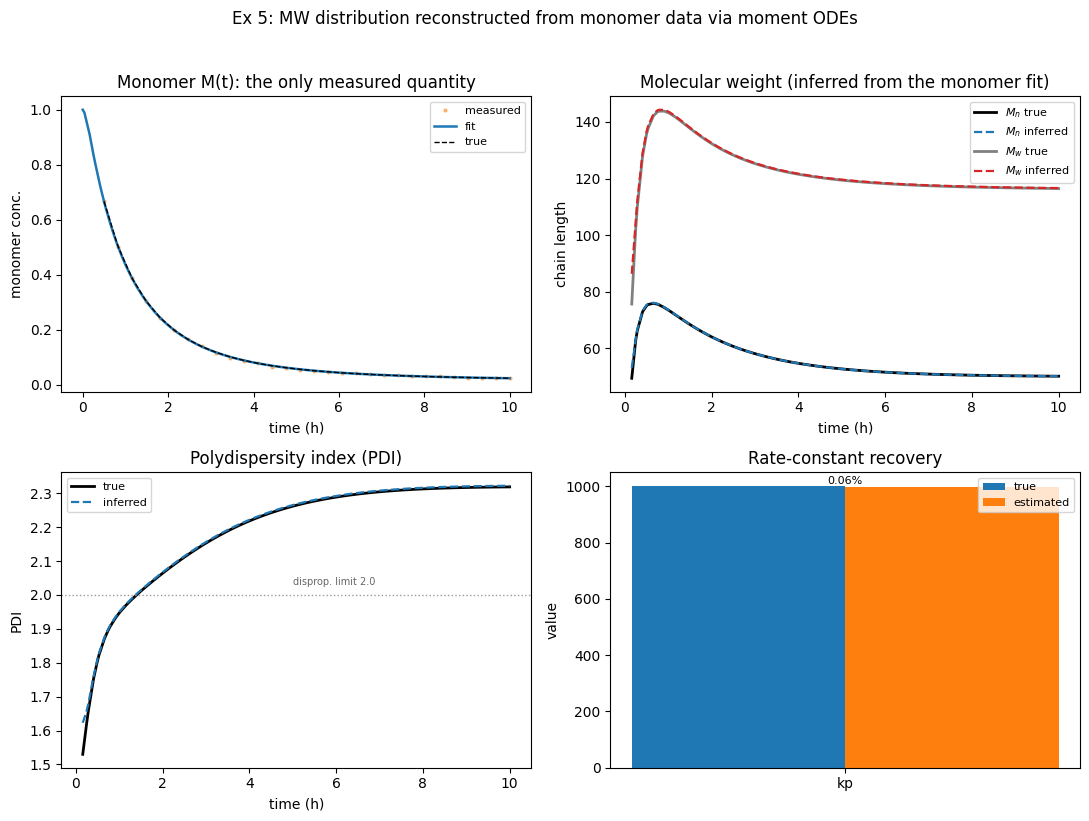

In [19]:
import matplotlib.pyplot as plt

Z = ro.Z

fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# (a) Monomer M(t): the only measured quantity.
ax[0, 0].plot(df.index, df.iloc[:, 0], ls='', marker='.', ms=4, alpha=0.5,
              color='C1', label='measured')
ax[0, 0].plot(Z.index, Z['M'], 'C0-', lw=1.8, label='fit')
ax[0, 0].plot(T_DATA, M_true, 'k--', lw=1.0, label='true')
ax[0, 0].set(title='Monomer M(t): the only measured quantity',
             xlabel='time (h)', ylabel='monomer conc.')
ax[0, 0].legend(fontsize=8)

# Early on, essentially no dead chains exist (X0 ~ 0), so Mn=X1/X0 etc. are
# 0/0 and blow up. Mask to times where a meaningful polymer population exists.
x0f, x0t = X['X0'].values, Xt[5]
valid = (x0f > 1e-3 * np.nanmax(x0f)) & (x0t > 1e-3 * np.nanmax(x0t))
tg = t_grid[valid]

# (b) Number- and weight-average MW, inferred from the fit (never measured).
ax[0, 1].plot(tg, Mn_t[valid], 'k-', lw=2, label='$M_n$ true')
ax[0, 1].plot(tg, Mn_f[valid], 'C0--', lw=1.6, label='$M_n$ inferred')
ax[0, 1].plot(tg, Mw_t[valid], color='0.5', lw=2, label='$M_w$ true')
ax[0, 1].plot(tg, Mw_f[valid], 'C3--', lw=1.6, label='$M_w$ inferred')
ax[0, 1].set(title='Molecular weight (inferred from the monomer fit)',
             xlabel='time (h)', ylabel='chain length')
ax[0, 1].legend(fontsize=8)

# (c) Polydispersity index over time.
ax[1, 0].plot(tg, PDI_t[valid], 'k-', lw=2, label='true')
ax[1, 0].plot(tg, PDI_f[valid], 'C0--', lw=1.6, label='inferred')
ax[1, 0].axhline(2.0, color='0.6', ls=':', lw=1)
ax[1, 0].text(t_grid[len(t_grid) // 2], 2.03, 'disprop. limit 2.0',
              fontsize=7, color='0.4')
ax[1, 0].set(title='Polydispersity index (PDI)',
             xlabel='time (h)', ylabel='PDI')
ax[1, 0].legend(fontsize=8)

# (d) Rate-constant recovery (only kp is free).
ax[1, 1].bar([-0.2], [KP], 0.4, label='true')
ax[1, 1].bar([0.2], [kp_hat], 0.4, label='estimated')
ax[1, 1].annotate(f'{err:.2f}%', (0.0, max(KP, kp_hat)), ha='center',
                  va='bottom', fontsize=8)
ax[1, 1].set_xticks([0.0])
ax[1, 1].set_xticklabels(['kp'])
ax[1, 1].set(title='Rate-constant recovery', ylabel='value')
ax[1, 1].legend(fontsize=8)

fig.suptitle('Ex 5: MW distribution reconstructed from monomer data via moment '
             'ODEs', y=1.02)
fig.tight_layout()